# Econ 5200 PS3 — The Rollout That Looked Like It Worked

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [14]:
# Card & Krueger (1994), from David Card's own archive
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

# given, continues
both = ck.dropna(subset=["fte_before", "fte_after"]).copy() # stores observed in both waves
both["nj"] = both["STATE"]  # 1 = New Jersey (treated), 0 = Pennsylvania

m = both.groupby("nj")[["fte_before", "fte_after"]].mean()
did_hand = ((m.loc[1, "fte_after"] - m.loc[1, "fte_before"]) - (m.loc[0, "fte_after"] - m.loc[0, "fte_before"]))
print(f"{len(both)} stores with both waves | 2x2 by hand {did_hand:.3f}")
assert round(did_hand, 2) == 2.75, "checkpoint failed. check FTE construction and the both-waves filter"


410 restaurants: 331 NJ, 79 PA
384 stores with both waves | 2x2 by hand 2.750


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [15]:
import statsmodels.formula.api as smf

cs_long = both.melt(id_vars=["SHEET", "nj"], value_vars=["fte_before", "fte_after"], var_name="wave", value_name="fte")
cs_long["post"] = (cs_long["wave"] == "fte_after").astype(int)
cs_long = cs_long.dropna(subset=["fte"])

fit_cs = smf.ols("fte ~ nj * post", data=cs_long).fit(cov_type="cluster", cov_kwds={"groups": cs_long["SHEET"]})   # each store appears twice
print(fit_cs.params.round(3))

gap_before = m.loc[1, "fte_before"] - m.loc[0, "fte_before"]
pa_change = m.loc[0, "fte_after"] - m.loc[0, "fte_before"]
assert abs(fit_cs.params["nj:post"] - did_hand) < 1e-8
assert abs(fit_cs.params["nj"] - gap_before) < 1e-8
assert abs(fit_cs.params["post"] - pa_change) < 1e-8


Intercept    23.380
nj           -2.949
post         -2.283
nj:post       2.750
dtype: float64


*Your answer here.*
the nj:post coefficient measures how much FTE employment changed in New Jersey compared to Pennsylvania. It equals my hand calculation of +2.75. The NJ coefficient is the baseline employment difference between the states, while post is the change in Pennsylvania over time. Neither is causal on its own. The interaction captures the difference between the two states changes and represents the policy effect only if New Jersey would have followed Pennsylvania's trend without the minimum wage increase. With only two periods, i cannot test the parrallel trend assumption.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [16]:
NEVER = 10**9
board_start = {0:3, 1:3, 2:4, 3:4, 4:5, 5:6, 6:6, 7:NEVER}  # first year of the program by board
growth_b = np.array([3, 3, 1.5, 1.5, 0.75, 0.25, 0.25, 0.0])  # effect per year of exposure by board
COUNTIES_PER_BOARD, YEARS = 5, 12
n_boards = len(board_start)
n_counties = n_boards * COUNTIES_PER_BOARD

board_of = np.repeat(np.arange(n_boards), COUNTIES_PER_BOARD) # board of each county
g_board = np.array([board_start[b] for b in range(n_boards)])

shock = rng.normal(0, 0.5, (n_boards, YEARS)) # board x year: shared by its 5 counties
level = rng.normal(0, 2, n_counties)  # each county's own level
noise = rng.normal(0, 0.8, (n_counties, YEARS)) # idiosyncratic

county = np.repeat(np.arange(n_counties), YEARS)
year = np.tile(np.arange(YEARS), n_counties)
board = board_of[county]
g = g_board[board]
D = (year >= g).astype(int)
true_eff = np.where(D == 1, growth_b[board] * (year - g + 1), 0.0)  # the truth on file for every row
y = 50 + level[county] + 0.5 * year + shock[board, year] + true_eff + noise.ravel()

counties = pd.DataFrame({"county": county, "year": year, "board": board, "D": D, "y": y, "true_eff": true_eff, "g": g, "board_shock": shock[board, year]})

# structure checks
assert len(counties) == 40 * 12 and counties['county'].nunique() == 40
assert (counties.groupby('county')['board'].nunique() == 1).all()
assert (counties.groupby('board')['county'].nunique() == 5).all()
assert (counties.groupby('board')['g'].nunique() == 1).all()  # adoption assigned by board
assert (counties.groupby(['board', 'year'])['board_shock'].nunique() == 1).all()  # shock shared in a board-year
assert counties.loc[counties['g'] < NEVER, 'g'].between(3, 6).all() # four-year window
assert (counties['g'] == NEVER).any() and counties['g'].min() >= 1  # a never board, pre-periods exist

true_att = counties.loc[counties['D'] == 1, 'true_eff'].mean()
low, high = counties.loc[counties['D'] == 1, 'true_eff'].agg(['min', 'max'])

twfe = smf.ols('y ~ D + C(county) + C(year)', data=counties).fit()
b_twfe = twfe.params['D']
print(f"treated county-years: {(counties['D'] == 1).sum()}")
print(f"TWFE {b_twfe:.3f}, true average effect on the treated {true_att:.3f}")
print(f"true effects on the treated range from {low:.2f} to {high:.2f}")



treated county-years: 265
TWFE -0.152, true average effect on the treated 7.726
true effects on the treated range from 0.25 to 27.00


*Your answer here.*
The agency's TWFE estimate is 0.52 with a true average effect on the treated of 7.726.

### Step 2.2: Decompose it (15 pts)

In [17]:
import itertools

T = YEARS
cohorts = sorted(counties["g"].unique())
N = {k: counties.loc[counties["g"] == k, "county"].nunique() for k in cohorts}
M = counties.groupby(["g", "year"])["y"].mean().unstack() # cohort x year means
Dbar = {k: (T - k) / T if k < NEVER else 0.0 for k in cohorts}  # share of periods treated

def did(treated, control, pre, post):
    return ((M.loc[treated, post].mean() - M.loc[treated, pre].mean()) - (M.loc[control, post].mean() - M.loc[control, pre].mean()))

rows = []
timing = [k for k in cohorts if k < NEVER]

# each timing cohort against the never-treated over the whole window
for k in timing:
    nk, nu = N[k], N[NEVER]
    nku = nk / (nk + nu)
    s = (nk + nu) ** 2 * nku * (1 - nku) * Dbar[k] * (1 - Dbar[k])
    est = did(k, NEVER, list(range(k)), list(range(k, T)))
    rows.append((k, NEVER, "treated vs never-treated", s, est))

# every pair of timing cohorts, in both roles
for k, l in itertools.combinations(timing, 2):  # k adopts before l
    nk, nl = N[k], N[l]
    nkl = nk / (nk + nl)
    # k treated, l not yet treated: window before l adopts
    s1 = (((nk + nl) * (1 - Dbar[l])) ** 2 * nkl * (1 - nkl) * ((Dbar[k] - Dbar[l]) / (1 - Dbar[l])) * ((1 - Dbar[k]) / (1 - Dbar[l])))
    rows.append((k, l, "early vs not-yet-treated (clean)", s1, did(k, l, list(range(k)), list(range(k, l)))))
    # l treated, k already treated as the control: window from k's adoption on
    s2 = (((nk + nl) * Dbar[k]) ** 2 * nkl * (1 - nkl) * (Dbar[l] / Dbar[k]) * ((Dbar[k] - Dbar[l]) / Dbar[k]))
    rows.append((l, k, "later vs already-treated (forbidden)", s2, did(l, k, list(range(k, l)), list(range(l, T)))))

bacon = pd.DataFrame(rows, columns=["treated_g", "control_g", "type", "s", "estimate"])
bacon["weight"] = bacon["s"] / bacon["s"].sum()
bacon["contribution"] = bacon["weight"] * bacon["estimate"]

assert abs(bacon["contribution"].sum() - b_twfe) < 1e-8, "decomposition must reproduce the TWFE coefficient"

summary = bacon.groupby("type").agg(comparisons=("weight", "size"), weight=("weight", "sum"), contribution=("contribution", "sum"))
summary["avg_2x2"] = summary["contribution"] / summary["weight"]
print(summary.round(3))
forbidden_share = summary.loc["later vs already-treated (forbidden)", "weight"]
print(f"\nshare of TWFE weight on forbidden comparisons: {forbidden_share:.1%}")
print(f"TWFE {b_twfe:.3f} vs true effects in [{low:.2f}, {high:.2f}]; true average {true_att:.3f}")
assert b_twfe < low, "TWFE should sit below the smallest true effect on this panel"


                                      comparisons  weight  contribution  \
type                                                                      
early vs not-yet-treated (clean)                6   0.203         0.609   
later vs already-treated (forbidden)            6   0.381        -3.310   
treated vs never-treated                        4   0.416         2.548   

                                      avg_2x2  
type                                           
early vs not-yet-treated (clean)        2.995  
later vs already-treated (forbidden)   -8.692  
treated vs never-treated                6.127  

share of TWFE weight on forbidden comparisons: 38.1%
TWFE -0.152 vs true effects in [0.25, 27.00]; true average 7.726


*Your answer here.*
TWFE is a weighted average of 16 different 2x2 comparisons, all with positive weights. Six of these use already-treated boards as controls and make up 38.1% of the total weight. They average -8.7 because the growing effect on the earlier-treated boards get mistaken for a normal time trend. The clean comparions average +3.0 and +6.1. this pulls the overall TWFE estimate down to -0.15, which is below the smallest true effect of 0.25, even though all the weights are positive. The weights apply to the 2x2 esimtates, not directly to the true estimate effects.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [18]:
# The reveal, continued: TWFE against an estimator that only uses not-yet-treated controls
NEVER = 10**9      # the cohort we give a unit that is never treated: later than any period

def clean_att(df):
    """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average."""
    out = []
    for g in sorted(df.loc[df["g"] < NEVER, "g"].unique()):
        treated = df[df["g"] == g]
        for t in range(g, df["t"].max() + 1):
            controls = df[df["g"] > t]                  # not yet treated at t
            if controls.empty:
                continue                                # nobody left to compare with
            d_tr = (treated.loc[treated["t"] == t, "y"].mean()
                    - treated.loc[treated["t"] == g - 1, "y"].mean())
            d_co = (controls.loc[controls["t"] == t, "y"].mean()
                    - controls.loc[controls["t"] == g - 1, "y"].mean())
            n = (treated["t"] == t).sum()               # treated units observed at t
            out.append({"g": g, "t": t, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
    return cells, np.average(cells["att"], weights=cells["n"])

panel = counties.rename(columns={'year':'t'}) # the given clean_att expects columns g, t, y

cells, att_clean = clean_att(panel)

print(f"{len(cells)} cells, clean ATT {att_clean:.3f}, truth {true_att:.3f}, TWFE {b_twfe:.3f}")
assert cells['n'].sum() == (counties['D'] == 1).sum()


30 cells, clean ATT 7.608, truth 7.726, TWFE -0.152


*Your answer here.*
Each cell compares a board cohort with boards that have not been treated yet in that year, including the never-treated board. Both changes are measured from the cohort's last year before treatment, so already-treated boards are never used as controls. The size-weighted average across the 30 comparisons is 7.61. which is close to the true average effect of 7.73. This is very differnt from the TWFE estimate of -0.15. The small 0.12 difference from the true effect is likely due to the sampling noise from the shocks affecting the weight boards.

### Step 3.2: The assumption you cannot test (12 pts)

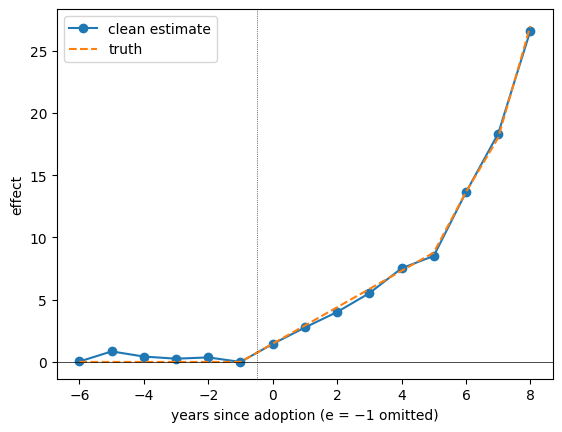

            -6    -5    -4    -3    -2   -1     0     1     2     3     4     5      6      7      8
estimate  0.03  0.85  0.43  0.26  0.36  0.0  1.44  2.77  4.01  5.52  7.52  8.52  13.63  18.34  26.61


In [19]:
cells['e'] = cells['t'] - cells['g']  # event time for the post cells

def pre_cells(df):
  """pre-period cells: cohort g in year t < g-1, base g-1, controls = cohorts adopting after g"""
  rows = []
  for g_ in sorted(c for c in df['g'].unique() if c < NEVER):
        tr, co, base = df[df['g'] == g_], df[df['g'] > g_], g_ - 1
        for t in range(0, base):
            d_tr = tr.loc[tr['year'] == t, 'y'].mean() - tr.loc[tr['year'] == base, 'y'].mean()
            d_co = co.loc[co['year'] == t, 'y'].mean() - co.loc[co['year'] == base, 'y'].mean()
            rows.append({'g': g_, 't': t, 'e': t - g_, 'att': d_tr - d_co, 'n': tr['county'].nunique()})
  return pd.DataFrame(rows)

REF = -1  # omitted period: last year before adoption
all_cells = pd.concat([pre_cells(counties), cells], ignore_index=True)
es = pd.Series({e: np.average(grp['att'], weights=grp['n']) for e, grp in all_cells.groupby('e')})
es.loc[REF] = 0.0
es = es.sort_index()
truth_path = (counties[counties['D'] == 1].assign(e=lambda d: d['year'] - d['g']).groupby('e')['true_eff'].mean().reindex(es.index).fillna(0.0))

fig, ax = plt.subplots()
ax.plot(es.index, es.values, 'o-', label='clean estimate')
ax.plot(truth_path.index, truth_path.values, '--', label='truth')
ax.axhline(0, color='k', lw=0.5)
ax.axvline(REF + 0.5, color='k', lw=0.5, ls=':')
ax.set_xlabel('years since adoption (e = −1 omitted)')
ax.set_ylabel('effect')
ax.legend()
plt.show()
print(es.round(2).to_frame('estimate').T.to_string())

assert es[REF] == 0 and es.index.min() == -6 and es.index.max() == 8


*Your answer here.*
I left out e=-1 because it is the baseline year for every cell. Each coefficient measures the change relative to that year, so including it would shift all the estimates. The pre-treatment estimates range from 0.03 to 0.85, which are fairly small. with only eight boards sharing shocks, differences this size could easily be due to noise alone, so they don't really support or go against parallel trends.
After adoption, the estimates increase with exposure and follow the true effect pattern, rising from 1,4 at e-0 to 26.6 at e=8. The later estiamtes are less precise because they are based on only one to three boards.
Overall, the flat pre-trends are consistent with parallel trends, but they don't prove the assumption. We cannot observe what adopting boards would have done without the program after adoption. We also have to assume boards did not choose when to adopt based on expected outcomes. The pre-treatment estimates help make the assumption more or less believeable, but cannot confirm it.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [20]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations

import itertools

import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

NEVER = 10 ** 9      # the cohort of a never-treated unit: later than any period

# Lab 11's functions, carried over

def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2: difference of differences of the four group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return float((g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0]))


def clean_att(df: pd.DataFrame, time: str = "t", outcome: str = "y",
              cohort: str = "g") -> tuple[pd.DataFrame, float]:
    """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average.

    Controls are units with cohort > t (never-treated included); both changes are
    measured from g - 1. Returns the cells (g, t, att, n) and the weighted mean.
    """
    out = []
    for g in sorted(df.loc[df[cohort] < NEVER, cohort].unique()):
        treated = df[df[cohort] == g]
        if (treated[time] == g - 1).sum() == 0:
            continue                                    # no baseline period for this cohort
        for t in range(g, df[time].max() + 1):
            controls = df[df[cohort] > t]
            if controls.empty:
                continue                                # nobody left to compare with
            d_tr = (treated.loc[treated[time] == t, outcome].mean()
                    - treated.loc[treated[time] == g - 1, outcome].mean())
            d_co = (controls.loc[controls[time] == t, outcome].mean()
                    - controls.loc[controls[time] == g - 1, outcome].mean())
            out.append({"g": g, "t": t, "att": d_tr - d_co,
                        "n": int((treated[time] == t).sum())})
    cells = pd.DataFrame(out)
    return cells, float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average ATT(g, t) cells by event time e, weighted by n (cells need columns e, att, n).

    Negative e are pre-treatment periods: a diagnostic, not a test of parallel trends.
    """
    rows = [{"e": e, "att": np.average(grp["att"], weights=grp["n"])}
            for e, grp in cells.groupby("e")]
    return pd.DataFrame(rows)


def pre_cells(df: pd.DataFrame, time: str, outcome: str, cohort: str,
              unit: str) -> pd.DataFrame:
    """Pre-period cells for cohort g in period t < g - 1, measured from base g - 1.

    Controls are cohorts adopting after g, so they are untreated in both periods compared.
    Returns columns g, t, e, att, n.
    """
    rows = []
    for g in sorted(c for c in df[cohort].unique() if c < NEVER):
        tr, co, base = df[df[cohort] == g], df[df[cohort] > g], g - 1
        for t in sorted(df.loc[df[time] < base, time].unique()):
            d_tr = tr.loc[tr[time] == t, outcome].mean() - tr.loc[tr[time] == base, outcome].mean()
            d_co = co.loc[co[time] == t, outcome].mean() - co.loc[co[time] == base, outcome].mean()
            rows.append({"g": g, "t": t, "e": t - g, "att": d_tr - d_co,
                         "n": tr[unit].nunique()})
    return pd.DataFrame(rows)


# your clustered-inference wrapper (Step 3.3)

def twfe_fit(df: pd.DataFrame, outcome: str, treat: str, unit: str, time: str,
             cluster: str | None = None):
    """TWFE fit `outcome ~ treat + C(unit) + C(time)`; cluster-robust SEs if `cluster` is given.

    The point estimate is the same either way; only the standard error changes.
    Cluster at the level where treatment was assigned.
    """
    model = smf.ols(f"{outcome} ~ {treat} + C({unit}) + C({time})", data=df)
    if cluster is None:
        return model.fit()
    return model.fit(cov_type="cluster", cov_kwds={"groups": df[cluster]})


# your bootstrap (Task 4.1)

def wild_cluster_bootstrap(df, cluster, y="y", treat="D", unit="county", time="year", max_G=14):
    """
    Wild cluster bootstrap-t, null imposed, Rademacher weights, full enumeration of 2^G sign vectors.
    Model: y ~ treat + unit FE + time FE (the TWFE/DiD regression). Cluster-robust t everywhere (CRV1).
    `cluster` is the column holding the cluster id (e.g. the regional board).
    """
    d = df.reset_index(drop=True)
    codes, labels = pd.factorize(d[cluster])
    G = len(labels)
    if G > max_G:
        raise ValueError(f"{G} clusters means 2^{G} weight vectors; enumeration is only sensible for small G.")

    fe = pd.get_dummies(d[[unit, time]].astype(str), drop_first=True, dtype=float)
    fe.insert(0, "const", 1.0)
    X_r = fe.to_numpy()                                   # restricted: no treatment term
    X_u = np.column_stack([d[treat].to_numpy(float), X_r])  # unrestricted: treatment is column 0
    yv = d[y].to_numpy(float)

    def fit_t(yy, use_t=False):
        res = sm.OLS(yy, X_u).fit(cov_type="cluster", cov_kwds={"groups": codes}, use_t=use_t)
        return res.params[0], res.tvalues[0], res

    # actual (unrestricted) estimate
    b, t_obs, res_u = fit_t(yv)

    # Step 1: restricted fit, treatment coefficient forced to zero
    res_r = sm.OLS(yv, X_r).fit()
    y_tilde, u_tilde = res_r.fittedvalues, res_r.resid

    # Step 2: all 2^G Rademacher vectors, one weight per cluster
    W = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))   # (2^G, G)

    # Steps 3-4: synthetic outcome, re-estimate unrestricted model, store cluster-robust t*
    t_star = np.empty(len(W))
    for k, w in enumerate(W):
        y_star = y_tilde + w[codes] * u_tilde
        t_star[k] = fit_t(y_star)[1]

    # Step 5: share of |t*| >= |t| (tolerance because w = +1 and w = -1 reproduce |t| up to rounding)
    p_boot = np.mean(np.abs(t_star) >= abs(t_obs) - 1e-8)

    p_norm = float(res_u.pvalues[0])                      # cluster-robust t, normal reference
    p_tG1 = float(fit_t(yv, use_t=True)[2].pvalues[0])    # cluster-robust t, t(G-1) reference
    return {"coef": b, "se_cluster": res_u.bse[0], "t": t_obs, "G": G, "n_vectors": len(W),
            "p_boot": p_boot, "p_cluster_normal": p_norm, "p_cluster_t_Gm1": p_tG1, "t_star": t_star}


def _toy_panel(effect: float = 2.0, seed: int = 0) -> pd.DataFrame:
    """8 boards x 5 counties x 12 years, constant true effect, one never-treated board."""
    rng = np.random.default_rng(seed)
    start = np.array([3, 3, 4, 4, 5, 6, 6, NEVER])
    shock = rng.normal(0, 0.5, (8, 12))
    level = rng.normal(0, 2, 40)
    noise = rng.normal(0, 0.8, (40, 12))
    county = np.repeat(np.arange(40), 12)
    year = np.tile(np.arange(12), 40)
    board = county // 5
    g = start[board]
    D = (year >= g).astype(int)
    y = 50 + level[county] + 0.5 * year + shock[board, year] + effect * D + noise.ravel()
    return pd.DataFrame({"county": county, "board": board, "g": g, "t": year,
                         "year": year, "D": D, "y": y})


if __name__ == "__main__":
    toy = _toy_panel()

    tiny = pd.DataFrame({"y": [1, 3, 2, 3], "tr": [1, 1, 0, 0], "post": [0, 1, 0, 1]})
    assert two_by_two(tiny, "y", "tr", "post") == 1.0                      # (3-1) - (3-2)

    cells, att = clean_att(toy)
    assert cells["n"].sum() == (toy["D"] == 1).sum()                       # every treated county-year once
    assert abs(att - 2.0) < 1.0                                            # truth is 2.0

    es = event_study(cells.assign(e=cells["t"] - cells["g"]))
    assert list(es["e"]) == list(range(0, 9))

    pc = pre_cells(toy, "t", "y", "g", "county")
    assert (pc["e"] <= -2).all() and pc["att"].abs().max() < 2

    f_default = twfe_fit(toy, "y", "D", "county", "year")
    f_board = twfe_fit(toy, "y", "D", "county", "year", cluster="board")
    assert f_board.n_groups == 8
    assert abs(f_board.params["D"] - f_default.params["D"]) < 1e-8         # only the SE changes
    assert f_board.bse["D"] > 0

    bs = wild_cluster_bootstrap(toy, cluster="board", y="y", treat="D", unit="county", time="year")
    assert abs(bs["coef"] - f_board.params["D"]) < 1e-8
    assert abs(bs["t"] - f_board.tvalues["D"]) < 1e-6                      # same CR1 t statistic
    assert bs["n_vectors"] == 256 and 0 <= bs["p_boot"] <= 1
    assert np.allclose(bs["t_star"], -bs["t_star"][::-1])                  # w and -w: opposite t*

    print("did_toolkit: all assertions pass")

Overwriting src/did_toolkit.py


In [21]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
# prove it runs: call each function on your panel
panel = counties.rename(columns={"year": "t"})                    # clean_att and pre_cells default to columns g, t, y

# two_by_two: cohort 3 vs never-treated, year 2 (before) vs year 5 (after)
two = counties[counties["g"].isin([3, dt.NEVER]) & counties["year"].isin([2, 5])].copy()
two["tr"], two["post"] = (two["g"] == 3).astype(int), (two["year"] == 5).astype(int)
est_2x2 = dt.two_by_two(two, "y", "tr", "post")
truth_2x2 = counties.loc[(counties["g"] == 3) & (counties["year"] == 5), "true_eff"].mean()
print(f"two_by_two {est_2x2:.2f} | truth {truth_2x2:.2f}")
assert abs(est_2x2 - truth_2x2) < 5                               # one cell, two treated boards: noisy

# clean_att: same cells and estimate as the notebook
cells_m, att_m = dt.clean_att(panel)
assert len(cells_m) == len(cells) and abs(att_m - att_clean) < 1e-12
print(f"clean_att {att_m:.3f} | truth {true_att:.3f}")

# event_study and pre_cells: the same event study as Step 3.2
cells_m["e"] = cells_m["t"] - cells_m["g"]
pre_m = dt.pre_cells(counties, "year", "y", "g", "county")
es_m = dt.event_study(pd.concat([pre_m, cells_m], ignore_index=True)).set_index("e")["att"]
assert abs(es_m[8] - es[8]) < 1e-9 and abs(es_m[-2] - es[-2]) < 1e-9

# twfe_fit: same estimate, SE grows with the right clustering
f_def = dt.twfe_fit(counties, "y", "D", "county", "year")
f_cty = dt.twfe_fit(counties, "y", "D", "county", "year", cluster="county")
f_brd = dt.twfe_fit(counties, "y", "D", "county", "year", cluster="board")
assert abs(f_brd.params["D"] - b_twfe) < 1e-8
assert f_brd.bse["D"] > f_cty.bse["D"] > f_def.bse["D"]
print(f"SEs {f_def.bse['D']:.3f} / {f_cty.bse['D']:.3f} / {f_brd.bse['D']:.3f}")

# wild_cluster_bootstrap: same output as Task 4.1
r_m = dt.wild_cluster_bootstrap(counties, cluster="board")
assert r_m["n_vectors"] == 256 and abs(r_m["coef"] - b_twfe) < 1e-8
assert abs(r_m["t"] - f_brd.tvalues["D"]) < 1e-6
print(f"bootstrap p {r_m['p_boot']:.3f}")
print("every did_toolkit function runs on the PS3 panel")



two_by_two 6.44 | truth 9.00
clean_att 7.608 | truth 7.726
SEs 0.725 / 1.416 / 3.314
bootstrap p 1.000
every did_toolkit function runs on the PS3 panel


*Your answer here.*
The estimate is -0.15 in all three cases. Only the standard error changes 0.73 with the default, 1.42 with county clustering, and 3.31 with board clustering. Board cluserting is the correct choice because treatment was assigned at the baord level, and the five counties within each board share the same yearly shocks. the default standard error treats all 480 observations as independent, ignoring these shared shocks and the correlation within counties over time. County clustering accounts for correlation within each county but treat counties in the same board as independent, een though they share the same shocks. This understates the uncertainty by more than half.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [22]:
import itertools
import numpy as np
import pandas as pd
import statsmodels.api as sm


def wild_cluster_bootstrap(df, cluster, y="y", treat="D", unit="county", time="year", max_G=14):
    """
    Wild cluster bootstrap-t, null imposed, Rademacher weights, full enumeration of 2^G sign vectors.
    Model: y ~ treat + unit FE + time FE (the TWFE/DiD regression). Cluster-robust t everywhere (CRV1).
    `cluster` is the column holding the cluster id (e.g. the regional board).
    """
    d = df.reset_index(drop=True)
    codes, labels = pd.factorize(d[cluster])
    G = len(labels)
    if G > max_G:
        raise ValueError(f"{G} clusters means 2^{G} weight vectors; enumeration is only sensible for small G.")

    fe = pd.get_dummies(d[[unit, time]].astype(str), drop_first=True, dtype=float)
    fe.insert(0, "const", 1.0)
    X_r = fe.to_numpy()                                   # restricted: no treatment term
    X_u = np.column_stack([d[treat].to_numpy(float), X_r])  # unrestricted: treatment is column 0
    yv = d[y].to_numpy(float)

    def fit_t(yy, use_t=False):
        res = sm.OLS(yy, X_u).fit(cov_type="cluster", cov_kwds={"groups": codes}, use_t=use_t)
        return res.params[0], res.tvalues[0], res

    # actual (unrestricted) estimate
    b, t_obs, res_u = fit_t(yv)

    # Step 1: restricted fit, treatment coefficient forced to zero
    res_r = sm.OLS(yv, X_r).fit()
    y_tilde, u_tilde = res_r.fittedvalues, res_r.resid

    # Step 2: all 2^G Rademacher vectors, one weight per cluster
    W = np.array(list(itertools.product([-1.0, 1.0], repeat=G)))   # (2^G, G)

    # Steps 3-4: synthetic outcome, re-estimate unrestricted model, store cluster-robust t*
    t_star = np.empty(len(W))
    for k, w in enumerate(W):
        y_star = y_tilde + w[codes] * u_tilde
        t_star[k] = fit_t(y_star)[1]

    # Step 5: share of |t*| >= |t| (tolerance because w = +1 and w = -1 reproduce |t| up to rounding)
    p_boot = np.mean(np.abs(t_star) >= abs(t_obs) - 1e-8)

    p_norm = float(res_u.pvalues[0])                      # cluster-robust t, normal reference
    p_tG1 = float(fit_t(yv, use_t=True)[2].pvalues[0])    # cluster-robust t, t(G-1) reference
    return {"coef": b, "se_cluster": res_u.bse[0], "t": t_obs, "G": G, "n_vectors": len(W),
            "p_boot": p_boot, "p_cluster_normal": p_norm, "p_cluster_t_Gm1": p_tG1, "t_star": t_star}

r = wild_cluster_bootstrap(counties, cluster="board")
print(r["coef"], r["se_cluster"], r["t"], r["p_cluster_normal"], r["p_cluster_t_Gm1"], r["p_boot"])


-0.15246080585727123 3.3140465882250676 -0.04600442443958701 0.9633067234522946 0.9645916530565992 1.0


*Your answer here.*
With only 8 boards, there are just 2^8 = 256 possible sign patterns. I can run through every one of them, so the bootstrap distribution is exact and the number of replications doesn’t matter. Flipping all the weights just flips the sign of t*, which leaves 128 distinct values of t*. The observed t is one of them, so the smallest p-value I can report is 2/256.

The TWFE coefficient is -0.15, with a board-clustered SE of 3.31 (t = -0.05). The standard cluster-robust p-value is 0.96, whether I use the normal or the t distribution with 7 df. The wild bootstrap p-value is 1.00. Either way, the conclusion is the same, the coefficient is indistinguishable from zero. And as step 2.2 showed, it’s also a biased estimate of the true effect 7.73.

### Task 4.2: The budget office memo

*Your answer here.*
Agency's estimate: The agency looked at counties before and after they joined the program and ran a standard regression. I tried the same method on test data where I had set the true effect. It gave -0.15. The real answer was 7.73, so the method was very inacurate.

Why this was wrong: Counties signed up in different years, and the program is more accurate the longer a county stays in it. The regression ends up measuring late joiners against counties that signed up earlier. Those earlier counties are already getting better because of the program, so the regression reads their progress as normal change and subtracts it. Roughly 38% of the agency’s figure comes from these comparisons. The flaw is in the method itself.

My estimate: I redid the analysis so that each group of counties was compared only with counties that hadn’t joined yet. That gave 7.61, which is very close to the true 7.73. The catch is that we only have eight regional boards, so this is a rough estimate. If you leave out any single board and the value shifts somewhere between 6.24 and 8.41. The agency’s number, meanwhile, is statistically no different from zero (p = 1.00).

Reccomendation: I reccomend you don't use the agency’s number, whether to defend the program or to criticise it. My estimate suggests the program works and that its benefits build over time, but eight boards can’t tell us the exact size. I recommend keeping the funding in place, with a condition attached: the program must be re-evaluated using only not-yet-enrolled counties as the comparison.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*

I originally left out e=-1 because it is the baseline year for every cell. Each coefficient measures the change relative to that year, so including it would shift all the estimates. The pre-treatment estimates range from 0.03 to 0.85, which are fairly small. with only eight boards sharing shocks, differences this size could easily be due to noise alone, so they don't really support or go against parallel trends. After adoption, the estimates increase with exposure and follow the true effect pattern, rising from 1,4 at e-0 to 26.6 at e=8. The later estiamtes are less precise because they are based on only one to three boards. Overall, the flat pre-trends are consistent with parallel trends, but they don't prove the assumption. We cannot observe what adopting boards would have done without the program after adoption. We also have to assume boards did not choose when to adopt based on expected outcomes. The pre-treatment estimates help make the assumption more or less believeable, but cannot confirm it.

I left out e=-1, the last year before adoption, so every coefficient is a change relative to that year. The pre-period estimates range from 0.03 to 0.85 in absolute value. I report no standard errors and with only eight boards the pre-period has little power, so it neither supports or undermines parallel trend. After adoption the estimates climb from 1.4 at e = 0 to 26.6 at e = 8. In this simulation we know the true path and the estimates track it. Some of the rise is composition, though by e = 8 only boards 0 and 1 are observed, and the single never-treated board is the control, so the latest estimates are the noisiest. Flat pre-trends are consistent with parallel trends but can’t prove them, since the assumption concerns the years after adoption. This caveat applies to any event-study estimator. The case against TWFE doesn’t rest on it, because the decomposition shows TWFE is biased through its forbidden comparisons.

| Objection | Verdict | Why | What I changed |
|---|---|---|---|
| "Noise alone" is unsupported.<br>Post effects dwarf pre deviations. | Accept in part | No pre-period SEs are computed.<br><br>So "small" was asserted, not shown.<br><br>The 30x comparison is off.<br><br>e = 8 uses 2 boards and 1 control.<br><br>Pre-period cells use many more. | Replaced the noise claim with a low-power statement.<br><br>Said I report no SEs.<br><br>Fixed late board counts.<br><br>Added a composition caveat.<br><br>Late cells aren't comparable with the pre-period. |
| "Not proven" is a DiD point.<br>Wrong estimator. | Reject, add one sentence | The caveat applies to every event study.<br><br>It stops flat pre-trends being read as proof.<br><br>The case against TWFE doesn't need parallel trends.<br><br>The decomposition shows the bias even if they hold. | Kept the caveat.<br><br>Added one sentence:<br><br>it applies to any event-study estimator.<br><br>The case against TWFE rests on the decomposition. |
| "Track the true path" means nothing in real data. | Accept | A true path exists only in the simulation.<br><br>The data-generating process is known by construction. | Limited the phrase to the simulated panel.<br><br>Added that real data offer no such benchmark. |

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

*Model and date:*

*Version 1 prompt:*
Act as the state agency's lead econometrician. You believe the
programme works and you are reading an external review that says your
TWFE estimate is uninformative.

[Request] Here is the reviewer's paragraph on parallel trends and
identification: I originally left out e=-1 because it is the baseline year for every cell. Each coefficient measures the change relative to that year, so including it would shift all the estimates. The pre-treatment estimates range from 0.03 to 0.85, which are fairly small. with only eight boards sharing shocks, differences this size could easily be due to noise alone, so they don't really support or go against parallel trends. After adoption, the estimates increase with exposure and follow the true effect pattern, rising from 1,4 at e-0 to 26.6 at e=8. The later estiamtes are less precise because they are based on only one to three boards. Overall, the flat pre-trends are consistent with parallel trends, but they don't prove the assumption. We cannot observe what adopting boards would have done without the program after adoption. We also have to assume boards did not choose when to adopt based on expected outcomes. The pre-treatment estimates help make the assumption more or less believeable, but cannot confirm it. Give the three strongest
objections you would raise in a written response.

[Evaluate] Rank them by how much damage each does to the reviewer's conclusion.

*Reply:*
1. The reviewer’s own estimator is validated only by a benchmark that real data can’t supply.
The paragraph says the estimates “follow the true effect pattern.” That is only knowable in a simulation. With real data there is no true path, and the reviewer admits the pre-period can’t confirm parallel trends. So nothing in this paragraph shows the event-study estimate is more credible than ours. The same caveats (unobservable untreated outcomes, possible strategic timing) apply to it, so “can’t be proven” can’t be used to call only our estimate uninformative.

2. The late estimates, the headline of the reviewer’s result, rest on almost nothing.
By the reviewer’s own account, the later estimates use only one to three boards. Every late cell is compared against a single never-treated board, so one unusual control path could drive the whole rise to 26.6. The composition also shifts as boards drop out of the panel, so part of the rise may reflect which boards are observed rather than exposure. “Less precise” is also never quantified, since no standard errors are reported. An estimator this fragile at its endpoints can’t be the benchmark that tells us our estimate is uninformative.

3. “Fairly small” and “noise alone” are asserted, not shown.
No standard errors are given for the pre-period cells, so there is no basis for saying noise explains them. The size claim is also relative to the wrong comparison. Deviations up to 0.85 look small next to 26.6, but the first post-period estimate is only 1.4. Pre-period wobble of that size is more than half the effect at adoption. The reviewer then argues that eight boards give too little power to learn anything, which undercuts the earlier claim that the deviations are just noise.

A note on how the reviewer will likely respond: objection 1 is the one they can best rebut. Their case against TWFE rests on the decomposition, which shows bias from forbidden comparisons even if parallel trends hold. So the identification caveat doesn’t carry their conclusion. I ranked it first because it does the most damage if the reviewer leans on this paragraph. Objections 2 and 3 are harder to answer, but they only weaken the event-study evidence, not the decomposition argument.

*Version 2 prompt:*
Some context of this is:
The reviewer argues that the agency’s two-way fixed effects (TWFE) estimate can’t recover the programme’s true effect. The paragraph below isn’t about that estimate, though. It interprets an event study built with a different method: each adopting group is compared with boards that haven’t adopted yet, and every change is measured from the last year before adoption. The data cover counties by year, with eight boards of five counties each that adopt in different years, plus one board that never adopts. Be specific and more concise about the three strongest objections to the argument. Say which part you disagree with, state why and say what the reviewer would have had to show

*Reply:*
bjection 1: The noise scale undercuts the reviewer.
Quote: “with only eight boards sharing shocks, differences this size could easily be due to noise alone, so they don't really support or go against parallel trends”
Problem: This sets 0.85 as the scale of noise, yet the post-adoption estimates climb from 1.4 to 26.6, about 30 times larger. If the noise claim is right, differential trends can’t explain the post-period. If it’s wrong, “small” and “noise” are unsupported.
Reviewer must show: Pre-period standard errors or intervals, and a plausible violation of parallel trends that starts at adoption and grows to about 26 units.

Objection 2: “Not proven” proves nothing specific.
Quote: “flat pre-trends are consistent with parallel trends, but they don't prove the assumption”
Problem: This applies to every difference-in-differences estimate, names no violation here, and concerns a different estimator than the TWFE estimate under dispute.
Reviewer must show: A concrete reason these boards’ untreated paths would diverge after adoption, and how that assumption bears on TWFE’s identification.

Objection 3: The late estimates are too thin to carry the argument.
Quote: “The later estimates are less precise because they are based on only one to three boards.”
Problem: The paragraph treats the rise to 26.6 as proof the estimator works, yet the endpoint rests on one to three boards, each compared with a single never-treated control. The rise may reflect which boards are observed, not exposure. “Less precise” is never quantified.
Reviewer must show: Standard errors for the late cells, and results with a balanced set of boards at each exposure length.

Ranking by damage:

Objection 1 (noise scale). It turns the reviewer’s own model against them. If 0.85 is noise, it can’t explain a rise to 26.6. If it isn’t, “small” and “noise” are unsupported. Only new evidence answers it.
Objection 3 (thin late estimates). It also needs new evidence (standard errors, balanced boards), but it only weakens the event-study evidence, not the wider claim.
Objection 2 (“not proven”). The reviewer can fall back on the burden of proof, since the caveat holds for any difference-in-differences estimate.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [25]:
print('Truth and headline numbers')
print('adoption years by board:', board_start, '  set in Step 2.1')
print('effect growth per year of exposure:', growth_b.tolist(), '  set in Step 2.1')
print('board-shock sd:', 0.5, '  set in Step 2.1')
print('seed:', 42, '  set in Setup')
# ... one line per memo number, with the cell that produced it
loo = {k: dt.clean_att(panel[panel["board"] != k])[1] for k in sorted(counties.loc[counties["g"] < NEVER, "board"].unique())}   # drop each treated board in turn

print(f'true average effect on treated county-years: {true_att:.2f} Step 2.1')
print(f'agency TWFE estimate: {b_twfe:.2f} Step 2.1')
print(f'share of TWFE weight on forbidden comparisons: {forbidden_share:.0%} Step 2.2')
print(f'clean estimate (not-yet-treated controls): {att_clean:.2f} Step 3.1')
print(f'clean estimate dropping one board, lowest / highest: {min(loo.values()):.2f} / {max(loo.values()):.2f} this cell')
print(f'TWFE SE, board-clustered: {r["se_cluster"]:.2f} Step 4.1')
print(f'TWFE p-value, wild cluster bootstrap: {r["p_boot"]:.2f} Step 4.1')


Truth and headline numbers
adoption years by board: {0: 3, 1: 3, 2: 4, 3: 4, 4: 5, 5: 6, 6: 6, 7: 1000000000}   set in Step 2.1
effect growth per year of exposure: [3.0, 3.0, 1.5, 1.5, 0.75, 0.25, 0.25, 0.0]   set in Step 2.1
board-shock sd: 0.5   set in Step 2.1
seed: 42   set in Setup
true average effect on treated county-years: 7.73 Step 2.1
agency TWFE estimate: -0.15 Step 2.1
share of TWFE weight on forbidden comparisons: 38% Step 2.2
clean estimate (not-yet-treated controls): 7.61 Step 3.1
clean estimate dropping one board, lowest / highest: 6.24 / 8.41 this cell
TWFE SE, board-clustered: 3.31 Step 4.1
TWFE p-value, wild cluster bootstrap: 1.00 Step 4.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.